In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd

Understanding Data 

In [3]:
df = sns.load_dataset("titanic")

df["family_size"] = df["sibsp"] + df["parch"] + 1

print(f"First 5 Rows : \n{df.head(5)}")

print(f"Dataset Dimensions : \n{df.shape}")

print(f"Column Names And Data Types : \n{df.dtypes}")

print(f"Dataset Information : ")
df.info()

print(f"Descriptive Statistics : \n{df.describe()}")

print(f"Missing Values : \n{df.isnull().sum()}")

print(f"\nDuplicate Rows:\n{df.duplicated().sum()}")

First 5 Rows : 
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  family_size  
0    man        True  NaN  Southampton    no  False            2  
1  woman       False    C    Cherbourg   yes  False            2  
2  woman       False  NaN  Southampton   yes   True            1  
3  woman       False    C  Southampton   yes  False            2  
4    man        True  NaN  Southampton    no   True            1  
Dataset Dimensions : 
(891, 16)
Column Names And Data Types : 
survived          int64
pclass            int64
sex           

Defining Questions

In [24]:
df["age_group"] = "Old"
df.loc[df["age"]<18 , "age_group"] = "Child"
df.loc[((df["age"]>=18) & (df["age"]<=35)) , "age_group"] = "Young"
df.loc[((df["age"]>=36) & (df["age"]<=59)) , "age_group"] = "Middle_Aged"
df.loc[df["age"].isna() , "age_group"] = None
df.loc[df["age"]>=60 , "age_group"] = "Old"

df["fare_group"] = "above_average"
df.loc[df["fare"]<df["fare"].mean() , "fare_group"] = "below_average"

gender_survived = df.groupby("sex")["survived"].mean() * 100
age_group_survived = df.groupby("age_group")["survived"].mean()*100
class_survived = df.groupby("pclass")["survived"].mean()*100
fare_survived = df.groupby("fare_group")["survived"].mean()*100
alone_survived = df.groupby("alone")["survived"].mean()*100
family_size_survived = df.groupby("family_size")["survived"].mean()*100
family_size_class_survived = df.groupby(["pclass" , "family_size"])["survived"].mean()*100
embarkation_survived = df.groupby("embarked")["survived"].mean()*100

print(f"gender_survived :\n{gender_survived}\n")
print(f"age_group_survived :\n{age_group_survived}\n")
print(f"class_survived :\n{class_survived}\n")
print(f"fare_survived :\n{fare_survived}\n")
print(f"alone_survived :\n{alone_survived}\n")
print(f"family_size_survived :\n{family_size_survived}\n")
print(f"family_size_class :\n{family_size_class_survived}\n")
print(f"embarkation_survived :\n{embarkation_survived}\n")

gender_survived :
sex
female    74.203822
male      18.890815
Name: survived, dtype: float64

age_group_survived :
age_group
Child          53.982301
Middle_Aged    39.790576
Old            26.923077
Young          38.020833
Name: survived, dtype: float64

class_survived :
pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64

fare_survived :
fare_group
above_average    59.715640
below_average    31.764706
Name: survived, dtype: float64

alone_survived :
alone
False    50.564972
True     30.353818
Name: survived, dtype: float64

family_size_survived :
family_size
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: survived, dtype: float64

family_size_class :
pclass  family_size
1       1               53.211009
        2               72.857143
        3               75.000000
        4               71.428571
        5              100.000000
        6      

Data Cleaning

In [25]:
empty_data = df.isna().sum()

df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])


print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))

#survived_alive :

mask_survived = (df["survived"] != 0) & (df["survived"] != 1)
df.loc[mask_survived, "survived"] = np.nan 

mask_alive = (df["alive"] != "no") & (df["alive"] != "yes")
df.loc[mask_alive , "alive"] = np.nan

df.loc[df["survived"] == 0, "alive"] = "no"
df.loc[df["survived"] == 1, "alive"] = "yes"

#pclass_class :	

mask_pclass = (df["pclass"] != 1) & (df["pclass"] != 2) & (df["pclass"] != 3)
df.loc[mask_pclass , "pclass"] = np.nan

mask_class = (df["class"] != "First") & (df["class"] != "Second") & (df["class"] != "Third")
df.loc[mask_class , "class"] = np.nan

df.loc[df["pclass"] == 1, "class"] = "First"
df.loc[df["pclass"] == 2, "class"] = "Second"
df.loc[df["pclass"] == 3, "class"] = "Third"

#age :

std_age = df["age"].std()
mean_age = df["age"].mean()
mask_age = ((mean_age-(2*std_age))>df["age"])|((mean_age+(2*std_age))<df["age"])
df.loc[mask_age , "age"] = np.nan

#fare :

std_fare = df["fare"].std()
mean_fare = df["fare"].mean()
mask_fare = ((mean_fare-(2*std_fare))>df["fare"])|((mean_fare+(2*std_fare))<df["fare"])
df.loc[mask_fare , "fare"] = np.nan

#parch_sibs_familysize_alone :

df["alone"] = df["alone"].astype("boolean")

mask_sibsp = (df["sibsp"] < 0)
df.loc[mask_sibsp, "sibsp"] = np.nan

mask_parch = (df["parch"] < 0)
df.loc[mask_parch, "parch"] = np.nan

mask_family_size = (df["family_size"] < 1)
df.loc[mask_family_size, "family_size"] = np.nan

mask_sibsp_parch_family_size_alone1 = (df["sibsp"]== 0) & (df["parch"] == 0) & (df["family_size"] == 1)
mask_sibsp_parch_family_size_alone2 = ((df["sibsp"]!= 0) | (df["parch"] != 0)) & (df["family_size"] > 1)
mask_sibsp_parch_family_size_alone3 = (df["sibsp"].isna()) | (df["parch"].isna()) | (df["family_size"].isna())

df.loc[mask_sibsp_parch_family_size_alone1 , "alone"] = True
df.loc[mask_sibsp_parch_family_size_alone2 , "alone"] = False
df.loc[mask_sibsp_parch_family_size_alone3 , "alone"] = np.nan

#sex_who :

mask_sex = (df["sex"]!="male")&(df["sex"]!="female")
df.loc[mask_sex , "sex"] = np.nan

mask_who = ( (df["who"] != "man") & (df["who"] != "woman") & (df["who"] != "child") )
df.loc[mask_who, "who"] = np.nan

df.loc[(df["sex"] == "male") & (df["who"] == "woman"), "who"] = "man"
df.loc[(df["sex"] == "female") & (df["who"] == "man"), "who"] = "woman"

colums_df = df.columns

for i in colums_df:

    if df[i].dtype == "int64":

        if df[i].min() >= 0 and df[i].max() <= 255:
            df[i] = df[i].astype("uint8")

        elif df[i].min() >= 0 and df[i].max() <= 65535:
            df[i] = df[i].astype("uint16")

        elif df[i].min() >= 0 and df[i].max() <= 4294967295:
            df[i] = df[i].astype("uint32")

        elif df[i].min() >= 0 and df[i].max() <= 18446744073709551615:
            df[i] = df[i].astype("uint64")

    elif df[i].dtype == "float64":
        df[i] = df[i].astype("float32")
        
df.to_csv("titanic_cleaned.csv" , index = False)

Duplicate rows: 107
Total rows: 891


Survival Rate - Fare - pie

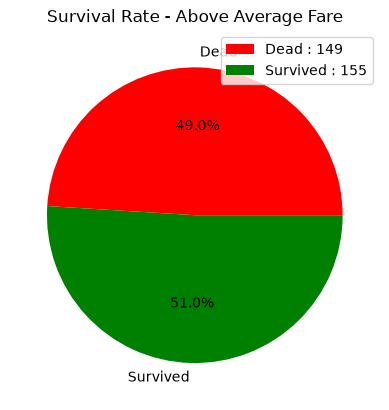

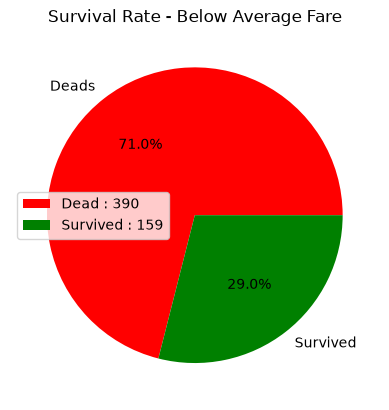

In [26]:
above_average = df[df["fare"]>=df["fare"].mean()]
below_average = df[df["fare"]<df["fare"].mean()]

above_average_dead = (above_average["survived"]==0).sum()
above_average_survived = (above_average["survived"]==1).sum()

below_average_dead = (below_average["survived"]==0).sum()
below_average_survived = (below_average["survived"]==1).sum()

plt.pie([above_average_dead , above_average_survived], labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Above Average Fare")
plt.legend(labels = [f"Dead : {above_average_dead} " , f"Survived : {above_average_survived}"])
plt.show()

plt.pie([below_average_dead , below_average_survived] , labels = ["Deads" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Below Average Fare")
plt.legend(labels =  [f"Dead : {below_average_dead} " , f"Survived : {below_average_survived}"])
plt.show()

Survival Rate - pclass - pie

Survival Rate - pclass_1 :


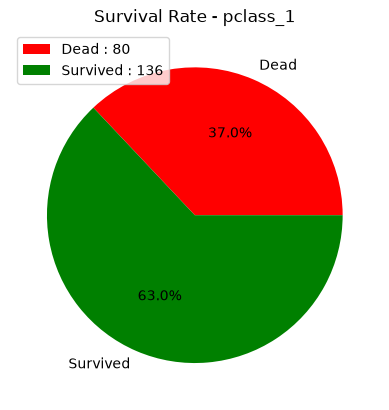

Survival Rate - pclass_2 :


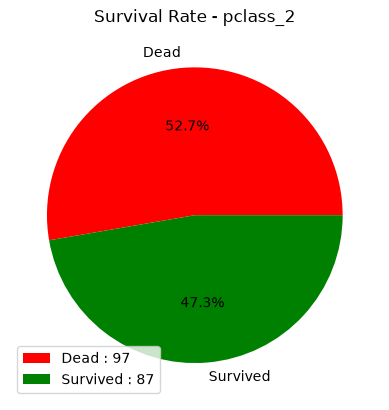

Survival Rate - pclass_3 :


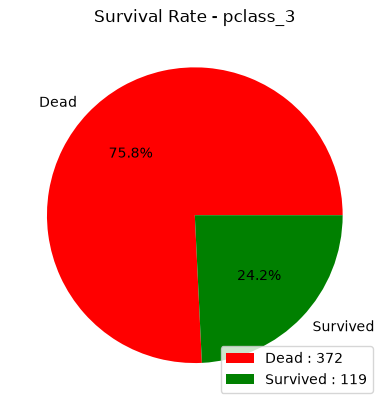

In [14]:
pclass_1 = df[df["pclass"] == 1]
pclass_2 = df[df["pclass"] == 2]
pclass_3 = df[df["pclass"] == 3]

pclass_1_dead = (pclass_1["survived"] == 0).sum()
pclass_1_survived = (pclass_1["survived"] == 1).sum()

pclass_2_dead = (pclass_2["survived"] == 0).sum()
pclass_2_survived = (pclass_2["survived"] == 1).sum()

pclass_3_dead = (pclass_3["survived"] == 0).sum()
pclass_3_survived = (pclass_3["survived"] == 1).sum()


print("Survival Rate - pclass_1 :")

plt.pie([pclass_1_dead , pclass_1_survived] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_1")
plt.legend(labels = [f"Dead : {pclass_1_dead} " , f"Survived : {pclass_1_survived}"])
plt.show()

print("Survival Rate - pclass_2 :")

plt.pie([pclass_2_dead , pclass_2_survived] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_2")
plt.legend(labels = [f"Dead : {pclass_2_dead} " , f"Survived : {pclass_2_survived}"])
plt.show()

print("Survival Rate - pclass_3 :")

plt.pie([pclass_3_dead , pclass_3_survived] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_3")
plt.legend(labels = [f"Dead : {pclass_3_dead} " , f"Survived : {pclass_3_survived}"])
plt.show()

Survival Rate - Age - pie - bar

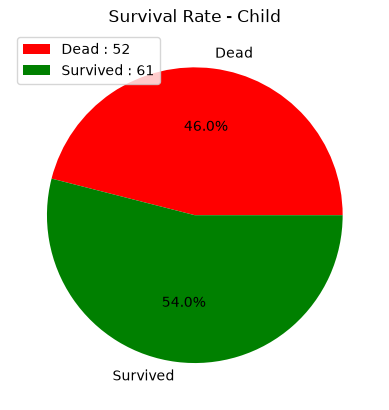

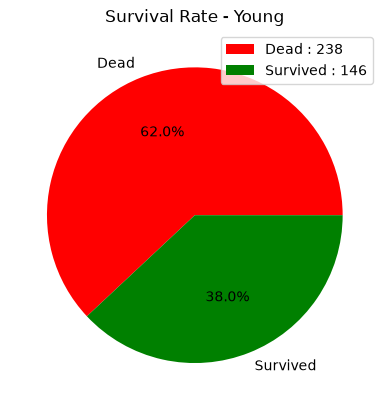

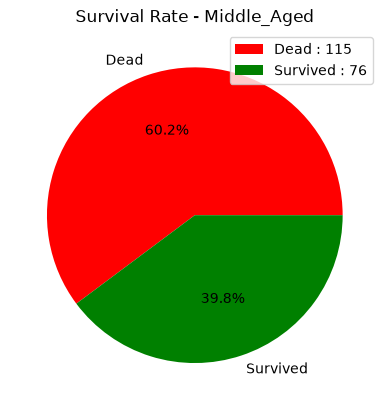

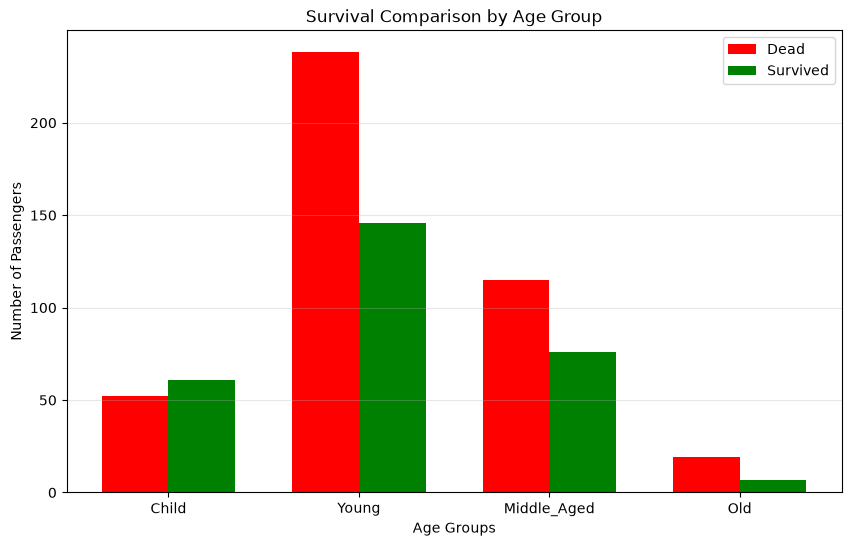

In [30]:
child = df[df["age"]<18]
Young =df[ (df["age"]>=18) & (df["age"]<=35)]
Middle_Aged = df[(df["age"]>=36) & (df["age"]<=59)]
old = df[df["age"]>=60]

dead_child = (child["survived"] == 0).sum()
survived_child = (child["survived"] == 1).sum()

dead_Young = (Young["survived"] == 0).sum()
survived_Young = (Young["survived"] == 1).sum()

dead_Middle_Aged = (Middle_Aged["survived"] == 0).sum()
survived_Middle_Aged = (Middle_Aged["survived"] == 1).sum()

dead_old = (old["survived"] == 0).sum()
survived_old = (old["survived"] == 1).sum()

plt.pie([dead_child , survived_child] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Child")
plt.legend(labels = [f"Dead : {dead_child}" , f"Survived : {survived_child}"])
plt.show()

plt.pie([dead_Young , survived_Young] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Young")
plt.legend(labels = [f"Dead : {dead_Young}" , f"Survived : {survived_Young}"])
plt.show()

plt.pie([dead_Middle_Aged , survived_Middle_Aged] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Middle_Aged")
plt.legend(labels = [f"Dead : {dead_Middle_Aged}" , f"Survived : {survived_Middle_Aged}"])
plt.show()

age_groups = ["Child", "Young", "Middle_Aged", "Old"]

dead_counts = [
    (df[(df["age"] < 18)]["survived"] == 0).sum(),
    (df[(df["age"] >= 18) & (df["age"] <= 35)]["survived"] == 0).sum(),
    (df[(df["age"] >= 36) & (df["age"] <= 59)]["survived"] == 0).sum(),
    (df[df["age"] >= 60]["survived"] == 0).sum()
]

survived_counts = [
    (df[df["age"] < 18]["survived"] == 1).sum(),
    (df[(df["age"] >= 18) & (df["age"] <= 35)]["survived"] == 1).sum(),
    (df[(df["age"] >= 36) & (df["age"] <= 59)]["survived"] == 1).sum(),
    (df[df["age"] >= 60]["survived"] == 1).sum()
]

x = np.arange(len(age_groups))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, dead_counts, width, label="Dead", color="red")
plt.bar(x + width/2, survived_counts, width, label="Survived", color="green")

plt.xticks(x, age_groups)
plt.xlabel("Age Groups")
plt.ylabel("Number of Passengers")
plt.title("Survival Comparison by Age Group")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

Age of Passengers

C:\Users\Hooman\AppData\Local\Temp\ipykernel_13704\2515315766.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


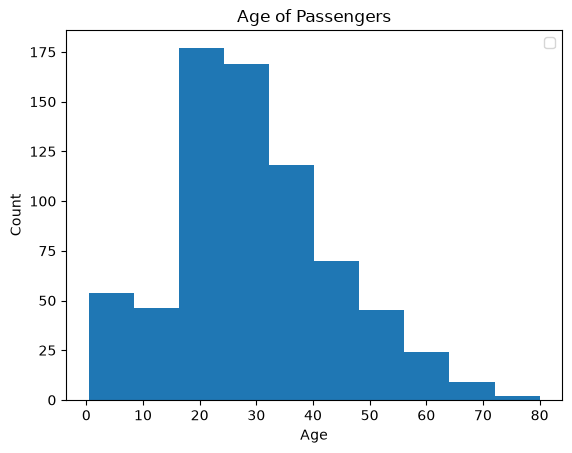

In [36]:
plt.hist(df[df["survived"] == 0][""])
plt.title("Age of Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

Fare Distribution by Survival Status


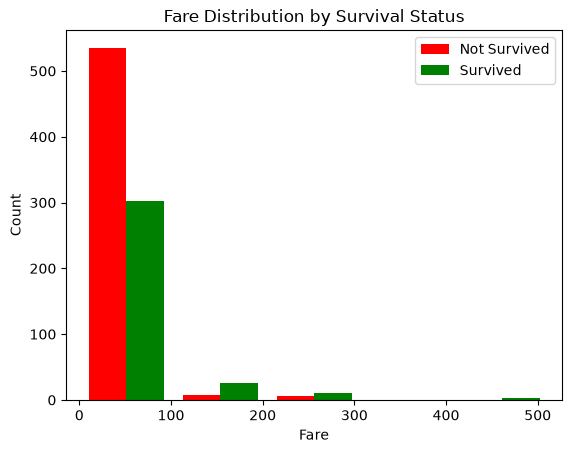

In [39]:
plt.hist([df[df["survived"] == 0]["fare"], df[df["survived"] == 1]["fare"]] , color = ["red" , "green"] , label = ["Not Survived", "Survived"] , bins = 5)
plt.title("Fare Distribution by Survival Status")
plt.xlabel("Fare")
plt.ylabel("Count")
plt.legend()
plt.show()

In [19]:
print(df.describe(include = "all"))
df

          survived      pclass   sex         age       sibsp       parch  \
count   891.000000  891.000000   891  714.000000  891.000000  891.000000   
unique         NaN         NaN     2         NaN         NaN         NaN   
top            NaN         NaN  male         NaN         NaN         NaN   
freq           NaN         NaN   577         NaN         NaN         NaN   
mean      0.383838    2.308642   NaN   29.699118    0.523008    0.381594   
std       0.486592    0.836071   NaN   14.526497    1.102743    0.806057   
min       0.000000    1.000000   NaN    0.420000    0.000000    0.000000   
25%       0.000000    2.000000   NaN   20.125000    0.000000    0.000000   
50%       0.000000    3.000000   NaN   28.000000    0.000000    0.000000   
75%       1.000000    3.000000   NaN   38.000000    1.000000    0.000000   
max       1.000000    3.000000   NaN   80.000000    8.000000    6.000000   

              fare embarked  class  who adult_male deck  embark_town alive  \
count   8

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,family_size
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,2
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,2
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,1
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,2
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,1
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,1
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,4
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,1
